# Pricing simulator (Lender 3)

This notebook turns default probabilities (PD) into interest-rate offers and tests pricing strategies by **replaying the 3-lender market on held-out past loans**.

**Why replaying works without past interest rates.** The past loans only tell us who defaulted, but in this game that is all we need:
- default does not depend on the rate charged (it is a property of the borrower), and all loans are 10,000 €;
- the borrower's choice rule is fully known (lowest rate after a 2% bonus for the preferred lender);
- the past loans contain all three signals, so we can rebuild what Lenders 1 and 2 would predict with their own signal.

The only true unknown is how rivals turn their PD into a rate, so we test several **rival scenarios** and look for a strategy that holds up across them.

**Profit of one loan won** (interest paid at maturity, zero recovery): `10,000 · [ r·(1 − D) − D ]`, so the **break-even rate** is `p / (1 − p)` (not `p`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]  # Okabe-Ito, colorblind-safe

LOAN = 10_000        # every loan is 10,000 €
BONUS = 0.02         # preferred lender's rate is treated as 2% lower by the borrower
N_APPLICANTS = 100_000
pd.set_option("display.width", 200)

## 1. Load held-out past loans with the three lenders' PDs

We reuse the **test-split** predictions of the three signal models (`signal{1,2,3}_models.ipynb`). They are out-of-sample: no model saw these 30,000 borrowers during training, so the replay is not over-optimistic.

- `p3`: our PD (public variables + `signal3`)
- `p1`, `p2`: proxies of what Lenders 1 and 2 can predict (same past data, their own signal)

In [2]:
PD_FILES = {
    "p1": "signal1_test_predictions_xgboost.csv",
    "p2": "signal2_test_predictions_spline.csv",
    "p3": "signal3_test_predictions_catboost.csv",
}
test = pd.read_csv(PROCESSED_DIR / "test.csv")
for col, file in PD_FILES.items():
    pds = pd.read_csv(PROCESSED_DIR / file)[["id", "pd"]].rename(columns={"pd": col})
    test = test.merge(pds, on="id", how="left", validate="one_to_one")
assert test[list(PD_FILES)].notna().all().all(), "a test borrower has no PD"

D = test["default"].to_numpy()
P = test[["p1", "p2", "p3"]].to_numpy()
S3_ZERO = (test["signal3"] == 0).to_numpy()
SCALE = N_APPLICANTS / len(test)  # report results per 100,000 applicants, like the real game

print(f"{len(test):,} held-out loans | default rate {D.mean():.2%} | mean PD L1/L2/L3: {P.mean(axis=0).round(4)}")
print(f"signal3 == 0 for {S3_ZERO.mean():.1%} of borrowers")

30,000 held-out loans | default rate 9.95% | mean PD L1/L2/L3: [0.0996 0.0996 0.1005]
signal3 == 0 for 20.9% of borrowers


## 2. Is our PD calibrated?

Pricing uses the **level** of the PD, not only its ranking (AUC), so predicted and realized default rates must match bucket by bucket.

        predicted  realized     n
decile                           
1           0.007     0.007  3000
2           0.019     0.025  3000
3           0.034     0.034  3000
4           0.054     0.053  3000
5           0.077     0.068  3000
6           0.102     0.102  3002
7           0.125     0.123  2999
8           0.149     0.143  2999
9           0.181     0.173  3006
10          0.258     0.268  2994


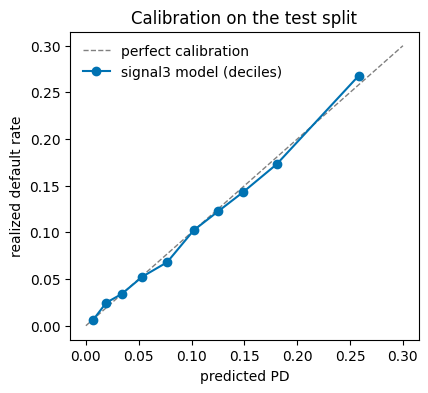

In [3]:
calib = (test.assign(decile=pd.qcut(test["p3"], 10, labels=False) + 1)
         .groupby("decile").agg(predicted=("p3", "mean"), realized=("default", "mean"), n=("id", "size")))
print(calib.round(3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot([0, 0.3], [0, 0.3], color="grey", lw=1, ls="--", label="perfect calibration")
ax.plot(calib["predicted"], calib["realized"], "o-", color=COLORS[0], label="signal3 model (deciles)")
ax.set(xlabel="predicted PD", ylabel="realized default rate", title="Calibration on the test split")
ax.legend(frameon=False)
plt.show()

## 3. Pricing strategies

A pricing strategy maps a PD to a rate, or to `NaN` (no offer). Rates above 100% are not allowed, so they become no offer.

| | Formula | Settings |
|---|---|---|
| **A** (linear, teammate) | `RF + (1 − RF) · p / thr`, no offer if `p ≥ thr` | `RF`, `thr` |
| **B** (break-even + flat) | `p/(1−p) + m` | `m` |
| **C** (break-even + growing) | `p/(1−p) + a + b·p` | `a`, `b` |

Add-ons for B and C: `z` = extra margin when `signal3 == 0` (we have no private information on those borrowers), `p_max` = no offer at or above this PD.

In [4]:
def break_even(p):
    """Rate with zero expected profit: r·(1 − p) = p."""
    return p / (1 - p)


def finalize(rate, p, p_max=1.0):
    """No offer above the PD cutoff or above the 100% rate cap."""
    return np.where((p >= p_max) | (rate > 1), np.nan, rate)


def strategy_a(p, rf, thr):
    return finalize(rf + (1 - rf) * p / thr, p, p_max=thr)


def strategy_b(p, m, z=0.0, s3_zero=None, p_max=1.0):
    extra = z * s3_zero if s3_zero is not None else 0.0
    return finalize(break_even(p) + m + extra, p, p_max)


def strategy_c(p, a, b, z=0.0, s3_zero=None, p_max=1.0):
    extra = z * s3_zero if s3_zero is not None else 0.0
    return finalize(break_even(p) + a + b * p + extra, p, p_max)

## 4. Market simulator

For each borrower and each lender `k` we have a rate `r_k` (`NaN` = no offer). Borrowers of type `t` (one third each, unobserved) subtract 2% from lender `t`'s rate and take the lowest.

Instead of drawing types at random, we **average over the three types exactly** (weight ⅓ each): this is the expected outcome of many random draws, without simulation noise. A lender's win weight on a borrower is therefore 0, ⅓, ⅔ or 1.

Outputs per lender: expected profit, loans won, realized default rate on won loans, and the **winner's-curse gap** = realized default on won loans − the lender's own mean PD on those loans.

In [5]:
def market(r1, r2, r3):
    """Replay the market; returns a per-lender summary and the (n, 3) win weights."""
    rates = np.column_stack([r1, r2, r3])
    offer = ~np.isnan(rates)
    rates_inf = np.where(offer, rates, np.inf)
    payoff = LOAN * (np.where(offer, rates, 0.0) * (1 - D[:, None]) - D[:, None])

    win = np.zeros_like(rates_inf)
    rows = np.arange(len(D))
    for preferred in range(3):
        effective = rates_inf.copy()
        effective[:, preferred] -= BONUS
        has_offer = np.isfinite(effective.min(axis=1))
        best = effective.argmin(axis=1)
        win[rows[has_offer], best[has_offer]] += 1 / 3

    won = win.sum(axis=0)
    summary = pd.DataFrame({
        "profit_eur": (win * payoff).sum(axis=0) * SCALE,
        "loans_won": won * SCALE,
        "default_on_won": (win * D[:, None]).sum(axis=0) / np.maximum(won, 1e-9),
        "mean_pd_on_won": (win * P).sum(axis=0) / np.maximum(won, 1e-9),
        "avg_rate_on_won": (win * np.where(offer, rates, 0.0)).sum(axis=0) / np.maximum(won, 1e-9),
    }, index=["Lender 1", "Lender 2", "Lender 3 (us)"])
    summary["winners_curse_gap"] = summary["default_on_won"] - summary["mean_pd_on_won"]
    return summary, win

### Sanity checks

1. **Everyone prices at break-even.** With unbiased models, each lender should *lose* money: each one wins the borrowers it underestimated (winner's curse).
2. **Rivals make no offer.** Our simulated profit must equal the direct sum `Σ 10,000·[r(1−D) − D]` over all our offers.

In [6]:
no_offer = np.full(len(D), np.nan)

summary, _ = market(break_even(P[:, 0]), break_even(P[:, 1]), break_even(P[:, 2]))
print("1) all lenders at break-even (per 100k applicants)")
print(summary.round(3), "\n")
assert (summary["profit_eur"] < 0).all(), "winner's curse should make break-even pricing lose money"

our_rate = break_even(P[:, 2]) + 0.02
summary, _ = market(no_offer, no_offer, our_rate)
direct = (LOAN * (our_rate * (1 - D) - D)).sum() * SCALE
print(f"2) monopoly check: simulator {summary.loc['Lender 3 (us)', 'profit_eur']:,.0f} € vs direct {direct:,.0f} €")
assert np.isclose(summary.loc["Lender 3 (us)", "profit_eur"], direct)

1) all lenders at break-even (per 100k applicants)
                profit_eur  loans_won  default_on_won  mean_pd_on_won  avg_rate_on_won  winners_curse_gap
Lender 1      -6429769.388  33156.667           0.100           0.084            0.096              0.016
Lender 2      -6810614.170  33428.889           0.100           0.083            0.094              0.017
Lender 3 (us) -6744485.854  33414.444           0.099           0.081            0.094              0.017 

2) monopoly check: simulator 19,091,517 € vs direct 19,091,517 €


## 5. Rival scenarios (team decision: edit this list)

Each scenario says how Lenders 1 and 2 turn their PD into a rate. We do not know which one is true, so we look for a strategy that holds up across them.

- **naive r=p**: a team copying the course slide formula (interest paid upfront), which underprices risk in this game
- **break-even**: rivals price at zero expected profit
- **BE+2%**, **BE+5%**: rivals add a flat margin
- **linear A**: rivals use the linear rule (RF = 2%, threshold = their 90th-percentile PD)
- **mixed**: Lender 1 at BE+1%, Lender 2 at BE+5%

In [7]:
p1, p2 = P[:, 0], P[:, 1]
RIVAL_SCENARIOS = {
    "naive r=p": (p1, p2),
    "break-even": (break_even(p1), break_even(p2)),
    "BE+2%": (break_even(p1) + 0.02, break_even(p2) + 0.02),
    "BE+5%": (break_even(p1) + 0.05, break_even(p2) + 0.05),
    "linear A": (strategy_a(p1, 0.02, np.quantile(p1, 0.9)), strategy_a(p2, 0.02, np.quantile(p2, 0.9))),
    "mixed": (break_even(p1) + 0.01, break_even(p2) + 0.05),
}
SCENARIOS = list(RIVAL_SCENARIOS)


def evaluate(our_rate):
    """Our expected profit (€, per 100k applicants) in every rival scenario."""
    return {name: market(r1, r2, our_rate)[0].loc["Lender 3 (us)", "profit_eur"]
            for name, (r1, r2) in RIVAL_SCENARIOS.items()}

## 6. Grid search over our settings

For every combination of settings we replay all scenarios and record our profit. Two summaries:
- **worst**: profit in the least favourable scenario (robust choice)
- **avg_ex_A**: average over scenarios, excluding *linear A* (rivals pricing very high make every strategy look great and would dominate a plain average)

In [8]:
grid = []
for rf in [0.0, 0.02, 0.04, 0.06]:
    for q in [0.8, 0.9, 0.95, 0.99]:
        grid.append({"strategy": "A", "rf": rf, "thr_quantile": q,
                     **evaluate(strategy_a(P[:, 2], rf, np.quantile(P[:, 2], q)))})
for m in np.arange(0.0, 0.151, 0.01):
    for z in [0.0, 0.03]:
        for p_max in [0.2, 0.3, 1.0]:
            grid.append({"strategy": "B", "m": m, "z": z, "p_max": p_max,
                         **evaluate(strategy_b(P[:, 2], m, z, S3_ZERO, p_max))})
for a in np.arange(-0.02, 0.041, 0.01):
    for b in np.arange(0.0, 3.51, 0.25):
        for z in [0.0, 0.03]:
            grid.append({"strategy": "C", "a": a, "b": b, "z": z,
                         **evaluate(strategy_c(P[:, 2], a, b, z, S3_ZERO))})

results = pd.DataFrame(grid).round({"a": 3, "b": 3, "m": 3})
results["worst"] = results[SCENARIOS].min(axis=1)
results["avg_ex_A"] = results[[s for s in SCENARIOS if s != "linear A"]].mean(axis=1)
print(f"{len(results)} settings evaluated")


def show_top(by, n=3):
    cols = ["strategy", "rf", "thr_quantile", "m", "a", "b", "z", "p_max"]
    top = (results.sort_values(by, ascending=False).groupby("strategy").head(n)
           .sort_values(["strategy", by], ascending=[True, False]))
    money = (top[SCENARIOS + ["worst", "avg_ex_A"]] / 1e3).round(0)
    return pd.concat([top[cols], money], axis=1).fillna("")


print("Best per strategy by WORST-case profit (k€ per 100k applicants)")
show_top("worst")

322 settings evaluated
Best per strategy by WORST-case profit (k€ per 100k applicants)


,strategy,rf,thr_quantile,m,a,b,z,p_max,naive r=p,break-even,BE+2%,BE+5%,linear A,mixed,worst,avg_ex_A
3,A,0.0,0.99,,,,,,332.0,208.0,799.0,3820.0,125045.0,728.0,208.0,1178.0
2,A,0.0,0.95,,,,,,194.0,200.0,664.0,2783.0,118205.0,534.0,194.0,875.0
1,A,0.0,0.9,,,,,,151.0,158.0,623.0,2419.0,75533.0,435.0,151.0,757.0
109,B,,,0.15,,,0.03,0.2,4.0,-449.0,-585.0,-619.0,83552.0,-558.0,-619.0,-441.0
106,B,,,0.15,,,0.0,0.2,4.0,-508.0,-648.0,-640.0,82202.0,-575.0,-648.0,-473.0
110,B,,,0.15,,,0.03,0.3,4.0,-524.0,-651.0,-754.0,92334.0,-603.0,-754.0,-506.0
190,C,,,,0.0,2.25,0.0,,301.0,289.0,835.0,3554.0,129379.0,743.0,289.0,1144.0
188,C,,,,0.0,2.0,0.0,,321.0,262.0,833.0,3824.0,126281.0,815.0,262.0,1211.0
192,C,,,,0.0,2.5,0.0,,267.0,259.0,843.0,3400.0,128886.0,698.0,259.0,1093.0


In [9]:
print("Best per strategy by AVERAGE profit excluding 'linear A' (k€ per 100k applicants)")
show_top("avg_ex_A")

Best per strategy by AVERAGE profit excluding 'linear A' (k€ per 100k applicants)


,strategy,rf,thr_quantile,m,a,b,z,p_max,naive r=p,break-even,BE+2%,BE+5%,linear A,mixed,worst,avg_ex_A
3,A,0.0,0.99,,,,,,332.0,208.0,799.0,3820.0,125045.0,728.0,208.0,1178.0
7,A,0.02,0.99,,,,,,25.0,9.0,677.0,3386.0,130942.0,318.0,9.0,883.0
2,A,0.0,0.95,,,,,,194.0,200.0,664.0,2783.0,118205.0,534.0,194.0,875.0
37,B,,,0.03,,,0.03,0.2,-1306.0,-1962.0,1792.0,10078.0,29337.0,1101.0,-1962.0,1941.0
34,B,,,0.03,,,0.0,0.2,-1566.0,-2465.0,2008.0,10326.0,25338.0,971.0,-2465.0,1855.0
31,B,,,0.02,,,0.03,0.2,-1621.0,-1789.0,902.0,8986.0,22386.0,1104.0,-1789.0,1516.0
208,C,,,,0.01,0.75,0.0,,-18.0,-400.0,1357.0,7562.0,70267.0,1337.0,-400.0,1968.0
236,C,,,,0.02,0.5,0.0,,-411.0,-887.0,1575.0,8338.0,59139.0,1068.0,-887.0,1937.0
206,C,,,,0.01,0.5,0.0,,168.0,-656.0,1059.0,7588.0,51179.0,1235.0,-656.0,1879.0


## 7. Profit curves: the trade-off behind the margin

For strategy C (with `a = 0`, `z = 3%`), profit as a function of `b` in each rival scenario. A higher `b` earns more per loan won but wins fewer, and safer, borrowers: the hump-shaped curve of the Scoring session.

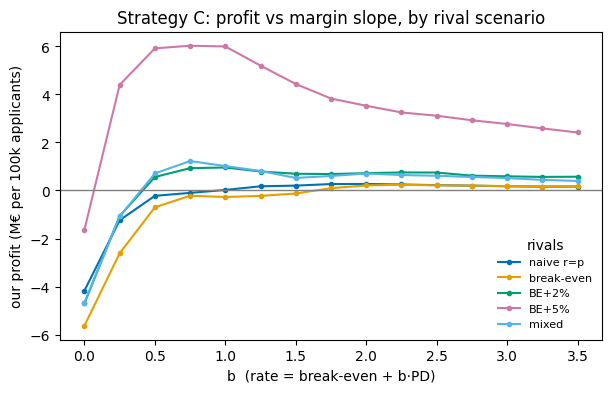

In [10]:
curve = results.query("strategy == 'C' and a == 0 and z == 0.03").sort_values("b")
fig, ax = plt.subplots(figsize=(7, 4))
for color, name in zip(COLORS, [s for s in SCENARIOS if s != "linear A"]):
    ax.plot(curve["b"], curve[name] / 1e6, "o-", ms=3, color=color, label=name)
ax.axhline(0, color="grey", lw=1)
ax.set(xlabel="b  (rate = break-even + b·PD)", ylabel="our profit (M€ per 100k applicants)",
       title="Strategy C: profit vs margin slope, by rival scenario")
ax.legend(title="rivals", frameon=False, fontsize=8)
plt.show()

## 8. Chosen policy (team decision)

**Edit `CHOSEN` after reviewing sections 6–7.** The default below is the most robust setting found (positive in every scenario tested); it is a placeholder, not a recommendation of the notebook.

The diagnostics show, in each scenario, how many loans we win, the default rate on them and the winner's-curse gap.

In [11]:
CHOSEN = {"strategy": "C", "a": 0.0, "b": 2.25, "z": 0.0, "p_max": 1.0}  # TEAM DECISION


def price(p, s3_zero, policy):
    if policy["strategy"] == "A":
        return strategy_a(p, policy["rf"], policy["thr"])
    if policy["strategy"] == "B":
        return strategy_b(p, policy["m"], policy.get("z", 0.0), s3_zero, policy.get("p_max", 1.0))
    return strategy_c(p, policy["a"], policy["b"], policy.get("z", 0.0), s3_zero, policy.get("p_max", 1.0))


chosen_rate = price(P[:, 2], S3_ZERO, CHOSEN)
diag = pd.DataFrame({name: market(r1, r2, chosen_rate)[0].loc["Lender 3 (us)"]
                     for name, (r1, r2) in RIVAL_SCENARIOS.items()}).T
print(f"Offer to {np.mean(~np.isnan(chosen_rate)):.1%} of borrowers, mean offered rate {np.nanmean(chosen_rate):.1%}")
diag.round(3)

Offer to 97.0% of borrowers, mean offered rate 32.0%


,profit_eur,loans_won,default_on_won,mean_pd_on_won,avg_rate_on_won,winners_curse_gap
naive r=p,3.011609e+05,2108.889,0.004,0.006,0.018,-0.002
break-even,2.891367e+05,2137.778,0.005,0.006,0.019,-0.001
BE+2%,8.346309e+05,4976.667,0.015,0.010,0.033,0.005
BE+5%,3.554271e+06,15557.778,0.018,0.013,0.042,0.005
linear A,1.293787e+08,78177.778,0.090,0.087,0.297,0.003
mixed,7.431821e+05,4996.667,0.013,0.009,0.029,0.004


## 9. Offers for the new applications

Same policy applied to the 100,000 new applicants (PD from the signal3 model refitted on all past loans). Missing rate = no offer.

Optional **Stage 1 experiment**: set `EXPERIMENT_SHARE > 0` to shift a random subset of rates by −1%, +1% or +2%. The random shift lets Stage 2 separate the effect of price from the effect of risk; the assignment is saved separately for that analysis.

In [12]:
EXPERIMENT_SHARE = 0.0  # TEAM DECISION, e.g. 0.2
EXPERIMENT_SHIFTS = [-0.01, 0.01, 0.02]

new = pd.read_csv(RAW_DIR / "NewApplications_Lender3_Round1.csv")
new_pd = pd.read_csv(PROCESSED_DIR / "signal3_new_applications_predictions_catboost.csv")[["id", "pd"]]
new = new.merge(new_pd, on="id", how="left", validate="one_to_one")
assert new["pd"].notna().all(), "a new applicant has no PD"

rate = price(new["pd"].to_numpy(), (new["signal3"] == 0).to_numpy(), CHOSEN)

rng = np.random.default_rng(SEED)
in_experiment = (rng.random(len(new)) < EXPERIMENT_SHARE) & ~np.isnan(rate)
shift = np.where(in_experiment, rng.choice(EXPERIMENT_SHIFTS, size=len(new)), 0.0)
rate = np.where(np.isnan(rate), np.nan, np.clip(rate + shift, 0.0001, 1.0))

offers = pd.DataFrame({"id": new["id"], "rate": rate.round(6)})
assert len(offers) == N_APPLICANTS and offers["id"].is_unique
assert set(offers["id"]) == set(range(1, N_APPLICANTS + 1))
assert offers["rate"].dropna().between(0, 1, inclusive="right").all()

offers.to_csv(PROCESSED_DIR / "stage1_offers_lender3.csv", index=False)
if EXPERIMENT_SHARE > 0:
    pd.DataFrame({"id": new["id"], "in_experiment": in_experiment, "shift": shift}).to_csv(
        PROCESSED_DIR / "stage1_experiment_assignment.csv", index=False)

print(f"Saved {len(offers):,} rows | offers: {offers['rate'].notna().mean():.1%} | "
      f"mean rate {offers['rate'].mean():.2%} | median {offers['rate'].median():.2%} | "
      f"in experiment: {in_experiment.mean():.1%}")
offers.head()

Saved 100,000 rows | offers: 97.3% | mean rate 31.82% | median 27.89% | in experiment: 0.0%


,id,rate
0,1,0.087008
1,2,0.384501
2,3,0.081990
3,4,0.261087
4,5,0.511080
